# Clase práctica: clustering y reducción de dimensionalidad

**Ruta de trabajo:** datos → preparación → K-means → clustering jerárquico → comparación → PCA para visualizar los grupos.

Al terminar podrás explicar por qué se escalan las variables, explorar el número de grupos, comparar dos particiones y representar sus resultados en dos dimensiones. Ejecuta las celdas en orden y responde las preguntas durante la práctica.

**Duración sugerida:** 90–120 minutos. **Requisitos:** Python con `numpy`, `pandas`, `matplotlib`, `scipy` y `scikit-learn`. Si faltan paquetes, instálalos en el entorno del cuaderno con `%pip install numpy pandas matplotlib scipy scikit-learn`.

El clustering es no supervisado: no usaremos etiquetas de referencia para ajustar los modelos ni para elegir el número de grupos.

## 1. Datos y pregunta

Usaremos Wine, incluido en scikit-learn: 178 vinos descritos mediante 13 mediciones químicas. La pregunta es: **¿qué agrupamientos sugieren estas mediciones y en qué se parecen los resultados de ambos métodos?**

La clase conocida del vino se reserva para una comparación externa posterior. No es una característica de entrada ni una verdad absoluta sobre cómo deberían agruparse las mediciones.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEMILLA = 42
pd.set_option('display.max_columns', None)

In [3]:
wine = load_wine(as_frame=True)
X = wine.data.copy()
clase_real = wine.target.copy()
print(f'Observaciones: {X.shape[0]}; variables: {X.shape[1]}')
print(f'Valores faltantes: {X.isna().sum().sum()}')
display(X.head())
display(X.describe().T[['mean', 'std', 'min', 'max']].round(2))

Observaciones: 178; variables: 13
Valores faltantes: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Pregunta:** ¿qué variables tienen escalas muy diferentes? ¿Por qué podría ser un problema al usar distancias euclidianas?

## 2. Preparación y estandarización

Revisamos datos faltantes y variables constantes antes de calcular distancias. Estandarizamos cada variable a media cero y desviación estándar uno. Esto no elimina los valores extremos y supone que todas las variables elegidas merecen participar en la distancia. En un problema con datos de entrenamiento y prueba, el escalador se ajusta solo con entrenamiento.

In [4]:
if X.isna().any().any():
    raise ValueError('Hay valores faltantes: revisa su origen y decide cómo tratarlos antes de continuar.')
if (X.nunique() <= 1).any():
    raise ValueError('Hay variables constantes: revísalas antes de continuar.')

escalador = StandardScaler()
X_escalado = pd.DataFrame(escalador.fit_transform(X), columns=X.columns, index=X.index)
display(X_escalado.describe().T[['mean', 'std', 'min', 'max']].round(2).head())

,mean,std,min,max
alcohol,-0.0,1.0,-2.43,2.26
malic_acid,-0.0,1.0,-1.43,3.11
ash,-0.0,1.0,-3.68,3.16
alcalinity_of_ash,-0.0,1.0,-2.67,3.15
magnesium,-0.0,1.0,-2.09,4.37


## 3. K-means: exploración de k

K-means asigna cada observación al centroide más cercano y busca reducir la **inercia**, suma de distancias euclidianas cuadradas a los centroides. Exploraremos el codo de la curva y el coeficiente **silueta** en el espacio de 13 variables estandarizadas.

La inercia tiende a disminuir al aumentar k; no se elige simplemente su valor mínimo. La silueta va de −1 a 1: valores mayores suelen indicar grupos más compactos y separados. Ambas son ayudas, no pruebas de un número verdadero de grupos.

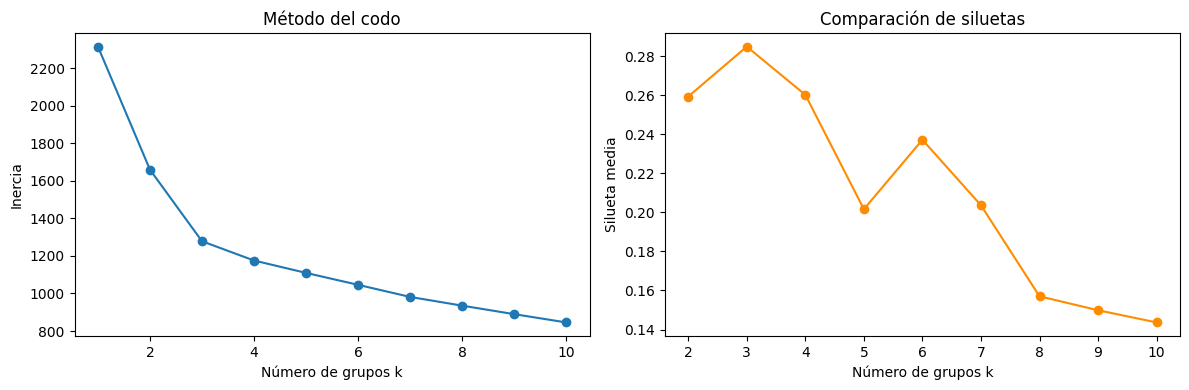

,k,silueta
1,3,0.285
2,4,0.260
0,2,0.259
4,6,0.237
5,7,0.204
3,5,0.202
6,8,0.157
7,9,0.150
8,10,0.144


In [6]:
valores_k = range(1, 11)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    if k >= 2:
        siluetas.append(silhouette_score(X_escalado, etiquetas))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(list(valores_k), inercias, marker='o')
ejes[0].set(xlabel='Número de grupos k', ylabel='Inercia', title='Método del codo')
ejes[1].plot(list(range(2, 11)), siluetas, marker='o', color='darkorange')
ejes[1].set(xlabel='Número de grupos k', ylabel='Silueta media', title='Comparación de siluetas')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'k': list(range(2, 11)), 'silueta': siluetas}).sort_values('silueta', ascending=False).round(3))

**Discusión:** ¿dónde se observa un posible codo? ¿Qué valor de k tiene la mayor silueta? ¿Coinciden los criterios?

Para esta práctica utilizamos **k = 3 como elección didáctica**, no como conclusión demostrada. Cambia el valor y vuelve a ejecutar las celdas siguientes para evaluar otras opciones.

In [7]:
k_elegido = 3
if not 2 <= k_elegido < len(X_escalado):
    raise ValueError('Para calcular la silueta, k debe estar entre 2 y n - 1.')

kmeans = KMeans(n_clusters=k_elegido, n_init=10, random_state=SEMILLA)
grupo_kmeans = kmeans.fit_predict(X_escalado)
print('Inercia:', round(kmeans.inertia_, 2))
print('Silueta de K-means:', round(silhouette_score(X_escalado, grupo_kmeans), 3))
display(pd.Series(grupo_kmeans, name='grupo').value_counts().sort_index().rename('observaciones'))

Inercia: 1277.93
Silueta de K-means: 0.285


,observaciones
grupo,
0,65
1,51
2,62


## 4. Clustering jerárquico aglomerativo

Partimos de una observación por grupo y fusionamos grupos sucesivamente. Con **Ward** y distancia euclidiana, cada fusión busca el menor incremento de la variación dentro de los grupos. El dendrograma muestra las fusiones; su eje vertical representa la distancia de enlace, no el número de observaciones.

Construimos el árbol con las mismas variables estandarizadas y después lo cortamos para obtener el mismo número de grupos usado por K-means. La línea horizontal marca una distancia entre las dos fusiones que rodean ese corte. Si ambas fusiones ocurren a la misma altura, no existe una línea horizontal que produzca exactamente ese número de grupos. Esta elección facilita la comparación, pero no implica que sea el único corte razonable.

[[  9.          47.           1.16411367   2.        ]
 [131.         133.           1.19160238   2.        ]
 [ 11.          12.           1.20935571   2.        ]
 [ 15.          53.           1.22551046   2.        ]
 [ 92.         107.           1.24538798   2.        ]
 [ 34.          37.           1.26841838   2.        ]
 [  0.          20.           1.28789316   2.        ]
 [ 16.          17.           1.2917937    2.        ]
 [164.         172.           1.30048379   2.        ]
 [ 22.          29.           1.33566687   2.        ]
 [ 40.          56.           1.34447772   2.        ]
 [104.         116.           1.3521749    2.        ]
 [ 23.          24.           1.36268788   2.        ]
 [ 27.          38.           1.3653111    2.        ]
 [140.         142.           1.36740174   2.        ]
 [ 63.          98.           1.38402544   2.        ]
 [ 26.          57.           1.38676396   2.        ]
 [111.         125.           1.43794707   2.        ]
 [163.    

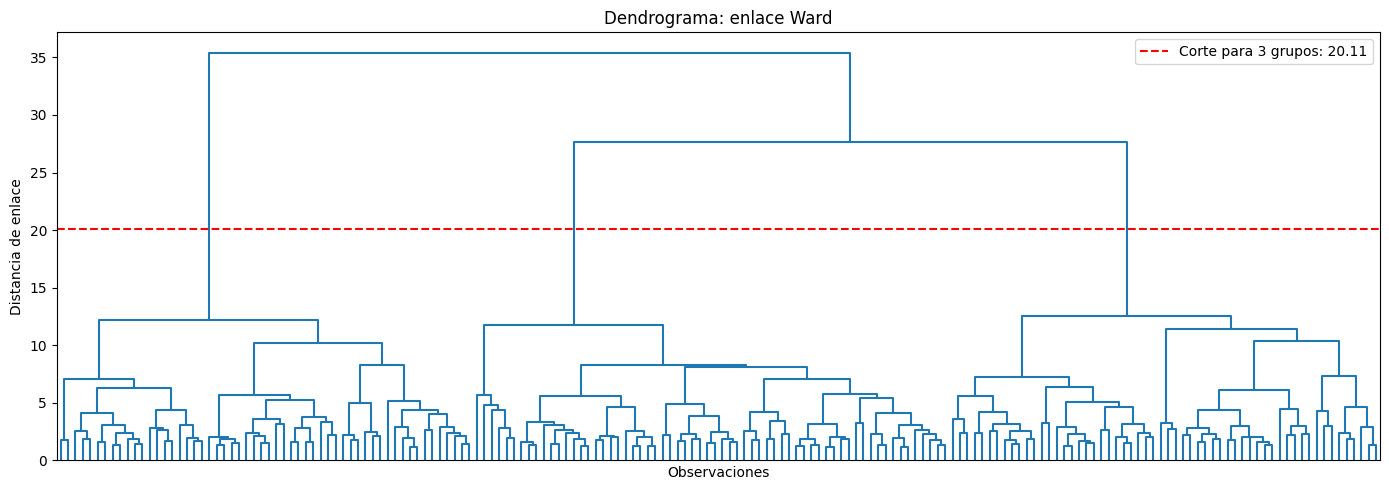

grupo jerárquico: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 2 2 1 1 1 0 0 1 2 1 2 0 1 0
 1 1 1 2 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 2 1 1 0 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
Silueta jerárquica: 0.277


,observaciones
grupo,
0,64
1,58
2,56


In [10]:
arbol = linkage(X_escalado, method='ward', metric='euclidean')
print(arbol)
altura_inferior = arbol[-k_elegido, 2]
altura_superior = arbol[-(k_elegido - 1), 2]
plt.figure(figsize=(14, 5))
dendrogram(arbol, no_labels=True, color_threshold=1)
if altura_inferior < altura_superior:
    distancia_corte = altura_inferior + (altura_superior - altura_inferior) / 2
    plt.axhline(distancia_corte, color='red', linestyle='--',
                label=f'Corte para {k_elegido} grupos: {distancia_corte:.2f}')
    plt.legend()
    print(f'Distancia de corte para {k_elegido} grupos: {distancia_corte:.2f}')
else:
    print('No hay una distancia de corte única para este número de grupos: hay fusiones a la misma altura.')
plt.title('Dendrograma: enlace Ward')
plt.xlabel('Observaciones')
plt.ylabel('Distancia de enlace')
plt.tight_layout()
plt.show()

grupo_jerarquico = cut_tree(arbol, n_clusters=k_elegido).ravel()
print('grupo jerárquico:', grupo_jerarquico)
print('Silueta jerárquica:', round(silhouette_score(X_escalado, grupo_jerarquico), 3))
display(pd.Series(grupo_jerarquico, name='grupo').value_counts().sort_index().rename('observaciones'))

**Pregunta:** ¿qué fusiones aparecen a distancias grandes? ¿Cómo cambiaría tu interpretación al cortar el árbol en otro nivel?

## 5. Comparar e interpretar los grupos

Comparamos tamaños y asignaciones, y calculamos el **índice Rand ajustado (ARI)**: 1 indica particiones idénticas y valores cercanos a 0 sugieren un acuerdo similar al esperado por azar; puede ser negativo. Los números de grupo son identificadores arbitrarios: el grupo 0 de un método no tiene por qué corresponder al grupo 0 del otro.

La silueta se calcula con las 13 variables estandarizadas, no con la proyección PCA. Para interpretar qué caracteriza a cada grupo, también examinamos las medias en las unidades originales.

In [ ]:
comparacion = pd.DataFrame({
    'K-means': grupo_kmeans,
    'Jerárquico': grupo_jerarquico,
}, index=X.index)
display(pd.crosstab(comparacion['K-means'], comparacion['Jerárquico']))
print('ARI entre métodos:', round(adjusted_rand_score(grupo_kmeans, grupo_jerarquico), 3))
display(pd.DataFrame({
    'Método': ['K-means', 'Jerárquico'],
    'Silueta': [silhouette_score(X_escalado, grupo_kmeans),
                 silhouette_score(X_escalado, grupo_jerarquico)]
}).round(3))

print('Medias por grupo de K-means, en unidades originales:')
display(X.groupby(grupo_kmeans).mean().round(2))
print('Medias por grupo jerárquico, en unidades originales:')
display(X.groupby(grupo_jerarquico).mean().round(2))

Jerárquico,0,1,2
K-means,,,
0,3,57,5
1,0,0,51
2,61,1,0


ARI entre métodos: 0.853


,Método,Silueta
0,K-means,0.285
1,Jerárquico,0.277


Medias por grupo de K-means, en unidades originales:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


Medias por grupo jerárquico, en unidades originales:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,13.67,1.97,2.46,17.53,106.16,2.85,3.01,0.29,1.91,5.45,1.07,3.16,1076.05
1,12.20,1.94,2.22,20.21,92.55,2.26,2.09,0.36,1.69,2.90,1.06,2.86,501.43
2,13.06,3.17,2.41,21.00,99.86,1.69,0.85,0.45,1.13,6.85,0.72,1.73,624.95


### Comparación opcional con una referencia externa

La clase conocida se usa **únicamente después** del agrupamiento. Una concordancia baja no demuestra por sí sola que el clustering sea incorrecto: las clases conocidas y las similitudes de las variables pueden reflejar criterios diferentes.

In [13]:
print('ARI K-means vs. clase conocida:', round(adjusted_rand_score(clase_real, grupo_kmeans), 3))
print('ARI jerárquico vs. clase conocida:', round(adjusted_rand_score(clase_real, grupo_jerarquico), 3))
display(pd.crosstab(clase_real.rename('Clase conocida'), comparacion['K-means']))
display(pd.crosstab(clase_real.rename('Clase conocida'), comparacion['Jerárquico']))

ARI K-means vs. clase conocida: 0.897
ARI jerárquico vs. clase conocida: 0.79


K-means,0,1,2
Clase conocida,,,
0,0,0,59
1,65,3,3
2,0,48,0


Jerárquico,0,1,2
Clase conocida,,,
0,59,0,0
1,5,58,8
2,0,0,48


## 6. Reducción a dos dimensiones para visualizar los clusters

**PCA** construye componentes lineales que capturan direcciones de variación de los datos. Ajustamos PCA sobre las mismas 13 variables estandarizadas **después** del clustering: solo proyectamos las observaciones y coloreamos con las etiquetas ya calculadas. No estamos agrupando de nuevo en el plano.

La varianza explicada indica cuánta variación conserva cada componente. Una proyección 2D pierde información: grupos solapados o separados en la gráfica pueden comportarse de otra manera en las 13 dimensiones. El tercer panel muestra las clases conocidas como referencia, sin haberlas usado para agrupar. Los colores identifican grupos o clases dentro de cada panel; no establecen correspondencia entre ellos.

Varianza explicada: PC1 = 36.2%, PC2 = 19.2%
Varianza explicada acumulada: 55.4%


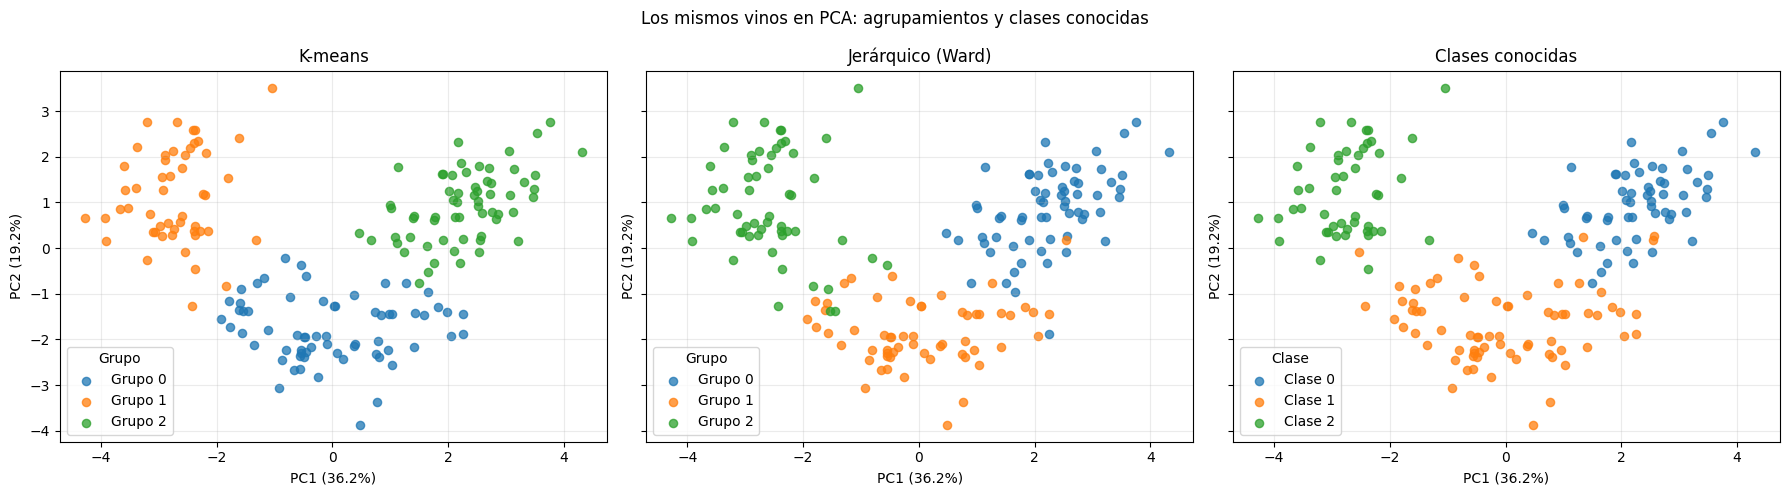

In [17]:
pca = PCA(n_components=2)
proyeccion = pca.fit_transform(X_escalado)
varianza = pca.explained_variance_ratio_
print(f'Varianza explicada: PC1 = {varianza[0]:.1%}, PC2 = {varianza[1]:.1%}')
print(f'Varianza explicada acumulada: {varianza.sum():.1%}')

fig, ejes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
paneles = [
    (grupo_kmeans, 'K-means', 'Grupo'),
    (grupo_jerarquico, 'Jerárquico (Ward)', 'Grupo'),
    (clase_real.to_numpy(), 'Clases conocidas', 'Clase'),
]
for eje, (etiquetas, titulo, tipo) in zip(ejes, paneles):
    for grupo in np.unique(etiquetas):
        mascara = etiquetas == grupo
        eje.scatter(proyeccion[mascara, 0], proyeccion[mascara, 1],
                    label=f'{tipo} {grupo}', alpha=0.75, s=35)
    eje.set(title=titulo, xlabel=f'PC1 ({varianza[0]:.1%})', ylabel=f'PC2 ({varianza[1]:.1%})')
    eje.legend(title=tipo)
    eje.grid(alpha=0.25)
fig.suptitle('Los mismos vinos en PCA: agrupamientos y clases conocidas')
plt.tight_layout()
plt.show()

## 7. Actividades y cierre

1. Justifica un valor de k usando la gráfica de inercia, la silueta y el dendrograma. Repite el análisis con otro valor y compara tamaños, siluetas y ARI.
2. Identifica dos variables que diferencien algunos grupos usando las tablas de medias. Explica sus unidades y evita interpretar el identificador de grupo como una jerarquía.
3. Compara los dos agrupamientos con las clases conocidas en los paneles PCA y explica qué se conserva y qué información puede perderse. ¿Coincide la impresión visual con la silueta calculada en el espacio original?
4. Prueba otro criterio jerárquico, por ejemplo `method='complete'`, manteniendo la distancia euclidiana. Compara dendrograma, silueta y ARI con Ward. Explica por qué cambiar el enlace puede cambiar los grupos.
5. **Conclusión:** redacta un párrafo sobre coincidencias, diferencias y limitaciones. No presentes los grupos como categorías naturales ni como relaciones causales.

**Para llevar:** el escalamiento y las decisiones de distancia afectan los grupos; las métricas y el dendrograma ayudan, pero no deciden solos; PCA facilita la visualización sin reemplazar la evaluación en el espacio utilizado para agrupar.